### Authentication vs Authorization  
Authentication (authn) answers 'who are you?'. Authorization (authz) answers 'what are you allowed to do?'. Authn always comes first, authz is checked on every request.  
• 401 Unauthorized really means 'not authenticated' (missing or bad credentials).  
• 403 Forbidden means 'authenticated, but not allowed'.  
• Three kinds of proof: something you know (password), something you have (phone, key), something you are (fingerprint). Combining two is MFA.  
• Two big architectures: stateful (server remembers you: sessions) and stateless (the request carries proof: JWT, API key signature).

### 1. Why should we never store passwords in plain text?  
Imagine you're building a chatbot application where users register with an email and password.
A user registers with:  

In [1]:
email = "user@example.com"
password = "MySecretPassword123"

A dangerous implementation stores the password directly in a database:  
User	Password  
user@example.com	MySecretPassword123  

**The problem?** Anyone who gains access to that database can immediately read every user's password.

This could happen because of a database breach, a compromised administrator account, an exposed backup, or an application vulnerability.

Even worse, people often reuse passwords across websites. A breach at your application could compromise their other accounts, too.

**The solution:** Never store the original password. Store a password hash instead.

### 2. What is password hashing?
Hashing transforms an input into a derived value using a mathematical algorithm.

```
Original password
(MySecretPassword123)
        |
Argon2id + random salt + configured cost
        |
Stored password hash
($argon2id$v=19$m=...$...$...)
```

A hash is designed to be one-way: you don't decrypt it to recover the password.

When the user logs in, you application hashes the candidates password using the stored hash's parameters and salt, the checks whether it matches.

Technically, with Argon2id, you generally call its verificatio function rather than manually hashing the password yourself.

One important distinction:
* **Encryption**: Reversible with the correct key.
* **Hashing**: Designed to be one-way.
* **Password hashing**: A specialized form of hashing deliberately made expensive to slow down guessing attacks.

### 3. Why not use MD5 or SHA-256?
You might wonder: Python supports SHA-256, so why not use it?

In [2]:
import hashlib

password = "MySecretPassword123"

digest = hashlib.sha256(password.encode()).hexdigest()

print(digest)

b169822e0e15ac5a2cccc3f740d5f263b501003d183928fc434653ecebd744bc


This code produces a hash, but it is not suitable for storing passwords.

The problem isn't that SHA-256 is broken for its intended purpose. It's that SHA-256 is designed to be fast.

Attackers who steal a password database can try billions of candidate password using higly optimised hardware, depending on the hardware and setup.

Compare the approaches:
| Property | SHA-256 | Argon2id |
|---|---|---|
| Designed to be fast | Yes | No |
| Random salt supported by algorithm itself | No; must be added separately | Supported by the password-hashing implementation |
| Configurable computational cost | No | Yes |
| Memory-intensive by design | No | Yes |
| Suitable for password storage | No, by itself | Yes |   

A regular SHA-256 digest is deterministic: the same input produces the same digest. That makes it fast to test guesses and easy to identify identical passwords if no salt is used.  
Argon2id is designed to make each guess more expensive in both processing time and memory.

### 4. What is a salt, and why do we need it?
A salt is a random value generated for each password hash.
Suppose two users choose the same password:

In [3]:
user_a_password = "Welcome123"
user_b_password = "Welcome123"

Without a salt, a deterministic password-hashing process would produce identical hashes for both users.

An attacker could recognise that the users have the same passowrd and use precomputed hash tables to acctack common passwords more efficiently.

With a unique random salt, the stored hashes differ even when the original passwords are identical.

#### Example without salt

In [5]:
import hashlib

password_a = user_a_password

digest_a = hashlib.sha256(password_a.encode()).hexdigest()

print(digest_a)

925d2e9bb3679c1b9dd58ab20bb974fdc61f3ff4db5e12bb54fab0600261c7b3


In [6]:
import hashlib

password_b = user_b_password

digest_b = hashlib.sha256(password_b.encode()).hexdigest()

print(digest_b)

925d2e9bb3679c1b9dd58ab20bb974fdc61f3ff4db5e12bb54fab0600261c7b3


In [7]:
digest_a == digest_b

True

#### Example with salt

In [9]:
from argon2 import PasswordHasher
from argon2.exceptions import VerifyMismatchError

ph = PasswordHasher()

In [10]:
stored_hash_a = ph.hash(user_a_password)

print(stored_hash_a)

$argon2id$v=19$m=65536,t=3,p=4$uOSoFZta2FkwQGh/STTQZA$pNizq371SV7878kgYu0HvR9Lh6BN79lA/xbFCyrwUfA


In [11]:
stored_hash_b = ph.hash(user_b_password)

print(stored_hash_b)

$argon2id$v=19$m=65536,t=3,p=4$pBPZgFwkO9cOuW/M8BW+Ig$KezbX4MC7OpyTMhM0THFoUGo3MK4oPnfVPvXtFDr/zg


In [16]:
stored_hash_a == stored_hash_b # Hash created is different becoz of salting

False

In [13]:
### Password verification
def check(password: str,  stored_hash: str) -> bool:
    try:
        return ph.verify(stored_hash, password)
    except VerifyMismatchError:
        return False

In [14]:
check(user_a_password, stored_hash_a)

True

In [15]:
check(user_b_password, stored_hash_b)

True

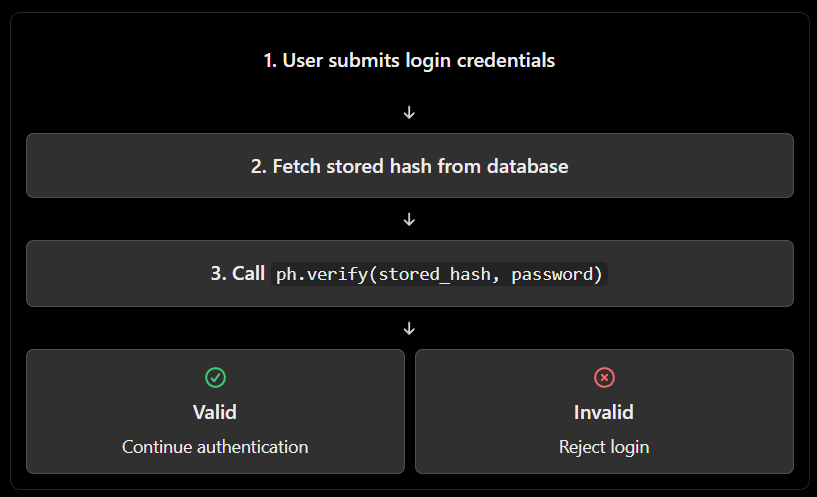

A salt does not need to be a secret. It is normally stored alongside the hash.
```
stored = ph.hash("correct horse battery staple")
```

The **Argon2** library automatically genetated a random salt and encodes it into the returend string along with the algorithm version, configuration parameters and derieved hash.

**Why is this useful?**
When verifying a password, the library can retireve the original salt and parameters from the stored string. You don't need a separate database column for the salt when using this format.

### 5. Why Argon2id is recommended?
Argon2id is a password-hashing algorithm designed to resist password-guessing attacks.

It combines two approaches:
* Argoin2i: Emphasizes resistance to certain side-channel attacks.
* Argon2d: Uses data-dependent memory access to make some attacks more difficult.

Argon2id combines characteristics of both.
Its 3 main configurable costs are:
| Parameter | Meaning |
|---|---|
| time_cost | Number of computational passes |
| memory_cost | Amount of memory used, in KiB |
| parallelism | Number of parallel lanes |   

For example:

In [8]:
from argon2 import PasswordHasher

ph = PasswordHasher(
    time_cost=3,
    memory_cost=65536,
    parallelism=4
)

Here, the memory cost is 65,536 KiB, approximately 64 MiB per hash operation.

These are illustrative configuration values, not a universal production setting.  You should benchmark the configuration on your actual server and tume it according to you security requirements, latency target and available resources.

Increasing the cost makes each password guess more expensive for an attacker, but it also increases the work on your own server must perform.

In production, you should also rate-limit login attempts, use TLS, avoid logging passwords, and protect authentication endpoints against abuse.
One additional detail: if the library raises an exception for a malformed or unsupported stored hash, don't automatically treat that as an ordinary wrong password. Handle invalid stored data separately and fail securely.

### 7. What is secrets.compare_digest() and why is it mentioned here?
Always compare secrets with secrets.compare_digest(a, b) (constant time) so attackers cannot learn bytes from timing differences.

This is related to a different security concern: timing attacks.
Consider a naive comparison:

In [17]:
def insecure_compare(a, b):
    for x, y in zip(a, b):
        if x != y:
            return False
    return len(a) == len(b)

This function returns as soon as it finds a mismatch.  
Suppose the expected secret is:
```
a7f91c
```

An attacker might observe that a candidate beginning with the correct initial bytes takes slightly longer to compare than one that differs immediately.

If an attacker can make many measurements under suitable conditions, timing differences may leak information about the secret.

Use Python's secrets module instead:

In [18]:
import secrets

expected = "a7f91c"
provided = "a7f91c"

if secrets.compare_digest(expected, provided):
    print("Match")
else:
    print("No match")

Match


compare_digest() is designed to avoid content-dependent short-circuit comparisons. For strings, both arguments must be ASCII-only; bytes are also supported.

It is not a guarantee that an entire application has perfectly constant execution time. Length differences, network behavior, and surrounding code may still leak information.

Important distinction: password verification versus secret comparison
You do not need to wrap the Argon2 result in secrets.compare_digest() when using ph.verify().

| Scenario | Correct approach |
|---|---|
| User password login | `ph.verify(stored_hash, candidate_password)` |
| Comparing API tokens or random secrets | `secrets.compare_digest(expected, provided)` |
| Verifying a password using SHA-256 and `compare_digest()` | Still not secure password storage; the hash is too fast |   

In other words, constant-time comparison and password hashing solve different problems. Constant-time comparison does not turn an unsuitable password hash into a suitable one.

### 8. Try it yourself
Here's a small standalone exercise combining registration and login.

In [21]:

from argon2 import PasswordHasher
from argon2.exceptions import VerifyMismatchError

ph = PasswordHasher()

def register(password: str) -> str:
    # Return the hash for database storage.
    return ph.hash(password)

def login(candidate: str, stored_hash: str) -> bool:
    try:
        return ph.verify(stored_hash, candidate)
    except VerifyMismatchError:
        return False

# Registration
db_hash = register("MyStrongPassword!2026")

# Login attempts
print(login("MyStrongPassword!2026", db_hash))
print(login("incorrect-password", db_hash))

# Hashing the same password again gives a different hash.
another_hash = register("MyStrongPassword!2026")
print(db_hash == another_hash)  # False


True
False
False


That final False is the key demonstration: the password is identical, but the random salts make the stored hash strings different.

Remember these four rules:
1. Never store passwords in plain text.
2. Use Argon2id, bcrypt, or scrypt rather than fast general-purpose hashes.
3. Use a unique random salt per password; established password-hashing libraries handle this for you.
4. Use ph.verify() for password authentication and secrets.compare_digest() when comparing other secret values.

### Registration Flow
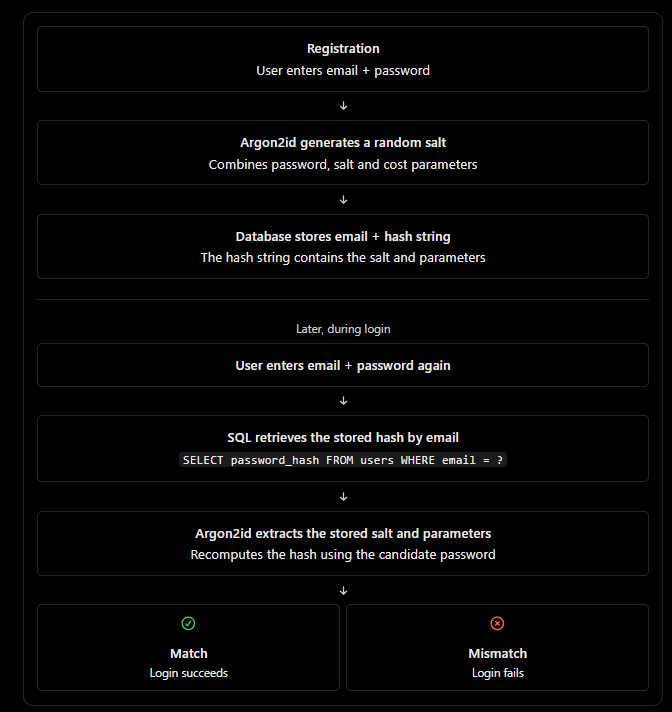

Salting happens during registration process:

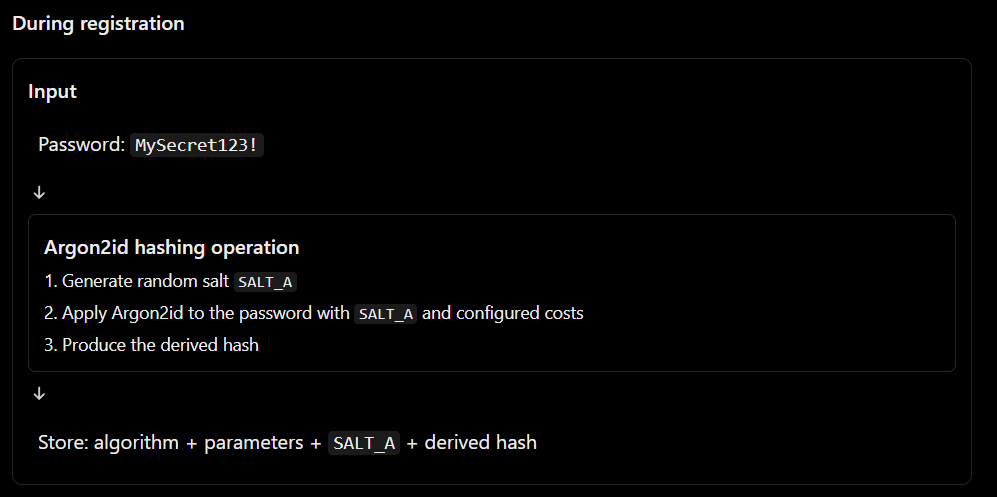

In [28]:

import sqlite3
from contextlib import closing
from getpass import getpass

from argon2 import PasswordHasher
from argon2.exceptions import (
    InvalidHashError,
    VerificationError,
    VerifyMismatchError,
)

DB_PATH = "app.db"


def database_setup() -> None:
    with closing(sqlite3.connect(DB_PATH)) as conn:
        with conn:
            conn.execute("""
                CREATE TABLE IF NOT EXISTS user_registration (
                    id INTEGER PRIMARY KEY,
                    email TEXT NOT NULL UNIQUE,
                    hash_key TEXT NOT NULL
                )
            """)


def store_hash_in_db(email: str, pwd_hash: str) -> bool:
    try:
        with closing(sqlite3.connect(DB_PATH)) as conn:
            with conn:
                conn.execute("""
                    INSERT INTO user_registration (email, hash_key)
                    VALUES (?, ?)
                """, (email, pwd_hash))

        return True

    except sqlite3.IntegrityError:
        # For example, email already exists.
        return False


def hash_lookup_in_db(email: str) -> str | None:
    with closing(sqlite3.connect(DB_PATH)) as conn:
        row = conn.execute("""
            SELECT hash_key
            FROM user_registration
            WHERE email = ?
        """, (email,)).fetchone()

    return row[0] if row is not None else None


def ask_user_activity() -> str:
    print("\nA -> Sign up")
    print("B -> Login")
    print("C -> Exit")

    choice = input("Select an activity: ").strip().upper()

    return {
        "A": "SIGN UP",
        "B": "LOGIN",
        "C": "EXIT",
    }.get(choice, "UNKNOWN")


def user_registration(hasher_obj: PasswordHasher) -> str:
    email = input("Enter your email address: ").strip().lower()
    password = getpass("Enter your password: ")

    if not email or not password:
        return "Email and password cannot be empty."

    # Generate the salted Argon2id hash.
    hash_generated = hasher_obj.hash(password)

    if store_hash_in_db(email, hash_generated):
        return "Registration successful."

    return "An account with this email already exists."


def user_login(hasher_obj: PasswordHasher) -> str:
    email = input("Enter your email address: ").strip().lower()
    password = getpass("Enter your password: ")

    if not email or not password:
        return "Email and password are required."

    stored_hash = hash_lookup_in_db(email)

    if stored_hash is None:
        return "Invalid email or password."

    try:
        if hasher_obj.verify(stored_hash, password):
            return "Authentication successful."

    except VerifyMismatchError:
        return "Invalid email or password."

    except (InvalidHashError, VerificationError):
        # Stored hash is malformed or verification failed.
        # In production, log this securely for investigation.
        return "Unable to verify credentials."

    return "Invalid email or password."


def main() -> None:
    print("Application started.")

    ph = PasswordHasher()
    database_setup()

    while True:
        user_choice = ask_user_activity()

        if user_choice == "EXIT":
            print("Application ended.")
            break

        elif user_choice == "SIGN UP":
            print(user_registration(ph))

        elif user_choice == "LOGIN":
            print(user_login(ph))

        else:
            print("Please select A, B, or C.")


if __name__ == "__main__":
    main()

Application started.

A -> Sign up
B -> Login
C -> Exit
Registration successful.

A -> Sign up
B -> Login
C -> Exit
Authentication successful.

A -> Sign up
B -> Login
C -> Exit
Application ended.
